# Análisis Exploratorio de Datos - Telecom Churn

Autor: Jorge Diaz

Objetivo: analizar la calidad, distribución y relaciones principales del dataset de telecomunicaciones antes de construir el modelo de predicción de fuga de clientes.

In [2]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

In [3]:
df = pd.read_csv("../data/telecom_churn_10000.csv")

df.head()

,CustomerID,Age,SeniorCitizen,Gender,Partner,Dependents,TenureMonths,TenureCohort,PhoneService,MultipleLines,...,SupportTickets,Complaints,CustomerContacts,ServiceOutages,NPS,CSAT,EstimatedCLV,AvgTicketCost,Churn,ChurnReason
0,TELCO-00001,46,0,M,No,Yes,72,61-72 months,Yes,Yes,...,0,0,4,0,8.0,5.0,8126.75,0.00,No,No churn
1,TELCO-00002,37,0,M,No,Yes,72,61-72 months,Yes,Yes,...,2,0,4,0,8.0,3.0,6655.91,0.93,No,No churn
2,TELCO-00003,48,0,F,Yes,No,35,25-36 months,Yes,No,...,0,0,1,1,5.0,3.0,3417.06,0.00,Yes,Poor customer service
3,TELCO-00004,60,1,F,No,No,53,49-60 months,Yes,No,...,1,0,4,0,10.0,4.0,5704.34,1.95,No,No churn
4,TELCO-00005,36,0,F,No,No,35,25-36 months,Yes,Yes,...,2,1,3,0,7.0,3.0,3916.51,0.83,Yes,Poor customer service


In [4]:
df.shape

(10000, 35)

In [5]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 10000 entries, 0 to 9999
Data columns (total 35 columns):
 #   Column            Non-Null Count  Dtype  
---  ------            --------------  -----  
 0   CustomerID        10000 non-null  str    
 1   Age               10000 non-null  int64  
 2   SeniorCitizen     10000 non-null  int64  
 3   Gender            10000 non-null  str    
 4   Partner           10000 non-null  str    
 5   Dependents        10000 non-null  str    
 6   TenureMonths      10000 non-null  int64  
 7   TenureCohort      10000 non-null  str    
 8   PhoneService      10000 non-null  str    
 9   MultipleLines     10000 non-null  str    
 10  InternetService   10000 non-null  str    
 11  OnlineSecurity    10000 non-null  str    
 12  OnlineBackup      10000 non-null  str    
 13  DeviceProtection  10000 non-null  str    
 14  TechSupport       10000 non-null  str    
 15  StreamingTV       10000 non-null  str    
 16  StreamingMovies   10000 non-null  str    
 17  Servi

In [6]:
df.isna().sum().sort_values(ascending=False)

PaymentMethod       150
NPS                 150
CSAT                150
MonthlyCharges      150
SeniorCitizen         0
CustomerID            0
Age                   0
Gender                0
Partner               0
Dependents            0
TenureMonths          0
OnlineSecurity        0
OnlineBackup          0
DeviceProtection      0
TechSupport           0
TenureCohort          0
PhoneService          0
MultipleLines         0
InternetService       0
Contract              0
ServiceCount          0
StreamingMovies       0
StreamingTV           0
DiscountRate          0
TotalCharges          0
AutoPay               0
PaperlessBilling      0
Complaints            0
SupportTickets        0
ServiceOutages        0
CustomerContacts      0
EstimatedCLV          0
AvgTicketCost         0
Churn                 0
ChurnReason           0
dtype: int64

In [7]:
df.duplicated().sum()

np.int64(0)

In [8]:
df["Churn"].value_counts()

Churn
No     5831
Yes    4169
Name: count, dtype: int64

In [9]:
df["Churn"].value_counts(normalize=True) * 100

Churn
No     58.31
Yes    41.69
Name: proportion, dtype: float64

## Balance de la variable objetivo

La variable objetivo `Churn` presenta una distribución de:

- 58,31 % de clientes que permanecen.
- 41,69 % de clientes que abandonan.

La diferencia entre ambas clases no es extrema, por lo que inicialmente se considera que el dataset presenta un balance adecuado para entrenar modelos de clasificación sin aplicar técnicas de remuestreo.

In [10]:
pd.crosstab(
    df["Contract"],
    df["Churn"],
    normalize="index"
) * 100

Churn,No,Yes
Contract,,
Month-to-month,49.873326,50.126674
One year,67.468406,32.531594
Two year,70.262246,29.737754


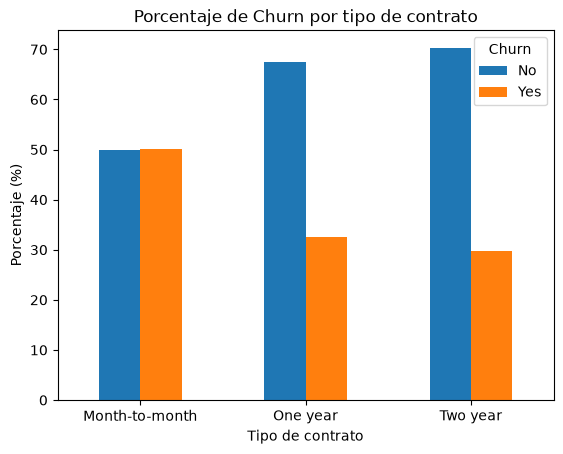

In [11]:
churn_contract = pd.crosstab(
    df["Contract"],
    df["Churn"],
    normalize="index"
) * 100

churn_contract.plot(kind="bar")
plt.title("Porcentaje de Churn por tipo de contrato")
plt.ylabel("Porcentaje (%)")
plt.xlabel("Tipo de contrato")
plt.xticks(rotation=0)
plt.show()

## Churn por tipo de contrato

Se observa una diferencia clara en la tasa de abandono según el tipo de contrato.

- Los clientes con contrato `Month-to-month` presentan la mayor proporción de churn, cercana al 50 %.
- En los contratos de `One year`, la proporción de abandono disminuye de forma importante.
- Los contratos de `Two year` presentan la menor tasa de churn.

Esto sugiere que una mayor permanencia contractual puede estar asociada con una menor probabilidad de abandono.

Desde una perspectiva de negocio, los clientes con contratos mensuales podrían ser un segmento prioritario para estrategias de retención.

In [12]:
df.groupby("Churn")["TenureMonths"].describe()

,count,mean,std,min,25%,50%,75%,max
Churn,,,,,,,,
No,5831.0,41.503859,20.863674,1.0,24.0,40.0,61.0,72.0
Yes,4169.0,29.946030,18.597262,1.0,16.0,26.0,40.0,72.0


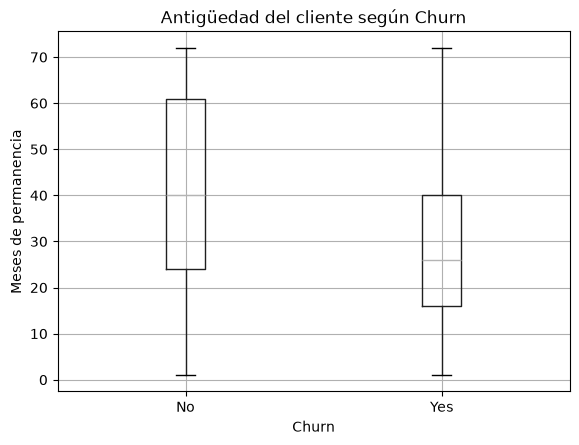

In [13]:
df.boxplot(column="TenureMonths", by="Churn")

plt.title("Antigüedad del cliente según Churn")
plt.suptitle("")
plt.xlabel("Churn")
plt.ylabel("Meses de permanencia")
plt.show()

## Antigüedad del cliente y Churn

Se observa que los clientes que presentan `Churn = Yes` tienden a tener una menor antigüedad en comparación con aquellos que permanecen en la compañía.

La mediana de `TenureMonths` es menor en el grupo que abandona, mientras que los clientes que permanecen presentan una distribución desplazada hacia mayores tiempos de permanencia.

Esto sugiere que los primeros meses de relación con el cliente pueden representar un período crítico para la retención.

Desde una perspectiva de negocio, podría ser útil priorizar acciones de acompañamiento, fidelización o seguimiento durante las etapas tempranas de la relación con el cliente.

In [14]:
df.groupby("Churn")["MonthlyCharges"].describe()

,count,mean,std,min,25%,50%,75%,max
Churn,,,,,,,,
No,5743.0,84.556700,23.884593,18.0,74.865,88.29,101.110,138.41
Yes,4107.0,92.204651,21.126174,18.0,82.565,94.78,106.365,138.96


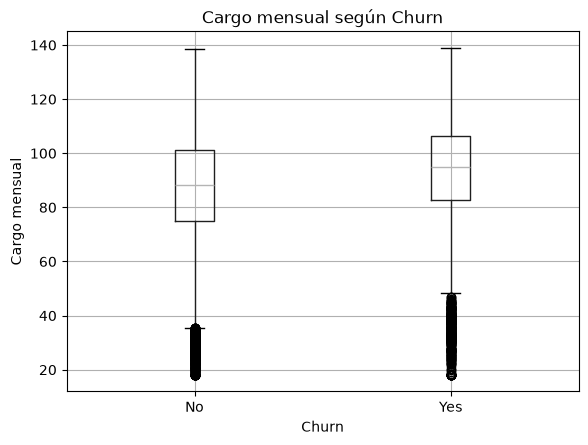

In [15]:
df.boxplot(column="MonthlyCharges", by="Churn")

plt.title("Cargo mensual según Churn")
plt.suptitle("")
plt.xlabel("Churn")
plt.ylabel("Cargo mensual")
plt.show()

## Cargo mensual y Churn

Los clientes que presentan `Churn = Yes` muestran, en general, cargos mensuales algo mayores que los clientes que permanecen.

Sin embargo, existe un solapamiento considerable entre ambos grupos, por lo que `MonthlyCharges` por sí sola no parece suficiente para explicar la fuga.

Esto sugiere que el nivel de cargo mensual puede contribuir al riesgo de abandono cuando se combina con otras variables, como el tipo de contrato, la antigüedad, la satisfacción o las quejas del cliente.

In [16]:
df.groupby("Churn")["NPS"].describe()

,count,mean,std,min,25%,50%,75%,max
Churn,,,,,,,,
No,5737.0,6.252920,1.678273,0.0,5.0,6.0,7.0,10.0
Yes,4113.0,5.924629,1.741896,0.0,5.0,6.0,7.0,10.0


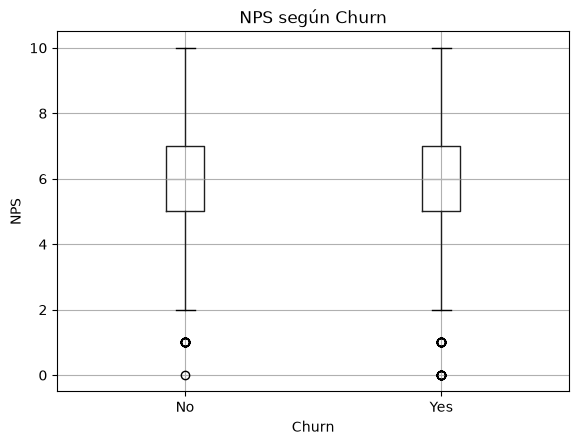

In [17]:
df.boxplot(column="NPS", by="Churn")

plt.title("NPS según Churn")
plt.suptitle("")
plt.xlabel("Churn")
plt.ylabel("NPS")
plt.show()

## NPS y Churn

La distribución de `NPS` es muy similar entre los clientes que permanecen y los que presentan churn.

Las medianas y los rangos de ambas categorías muestran un alto nivel de solapamiento, por lo que `NPS` de manera individual no parece tener una capacidad clara para diferenciar clientes con mayor riesgo de abandono.

Esto no significa que la variable no sea útil para el modelo. Su aporte podría aparecer al combinarse con otras variables como satisfacción (`CSAT`), quejas, antigüedad, contrato o número de contactos con servicio al cliente.

In [18]:
df.groupby("Churn")["CSAT"].describe()

,count,mean,std,min,25%,50%,75%,max
Churn,,,,,,,,
No,5737.0,3.512463,0.678849,1.0,3.0,4.0,4.0,5.0
Yes,4113.0,3.362509,0.681984,1.0,3.0,3.0,4.0,5.0


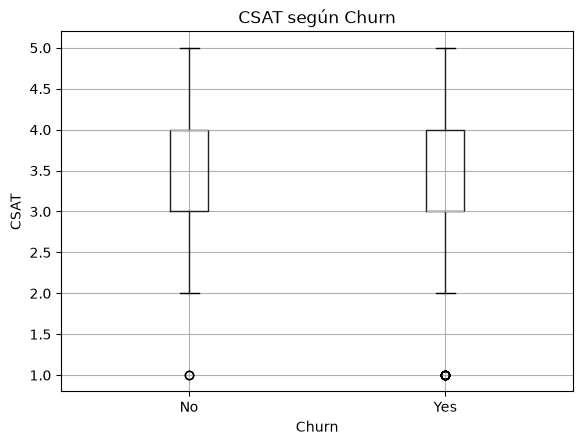

In [19]:
df.boxplot(column="CSAT", by="Churn")

plt.title("CSAT según Churn")
plt.suptitle("")
plt.xlabel("Churn")
plt.ylabel("CSAT")
plt.show()

In [20]:
df.groupby("Churn")[["Complaints", "SupportTickets", "CustomerContacts"]].mean()

,Complaints,SupportTickets,CustomerContacts
Churn,,,
No,0.440233,1.706911,3.656491
Yes,0.639002,2.089230,4.252579


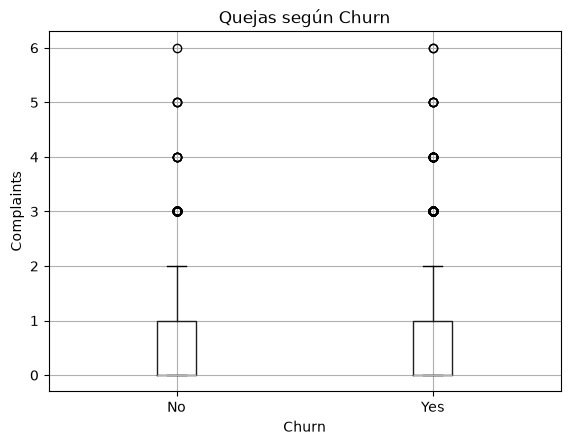

In [21]:
df.boxplot(column="Complaints", by="Churn")

plt.title("Quejas según Churn")
plt.suptitle("")
plt.xlabel("Churn")
plt.ylabel("Complaints")
plt.show()

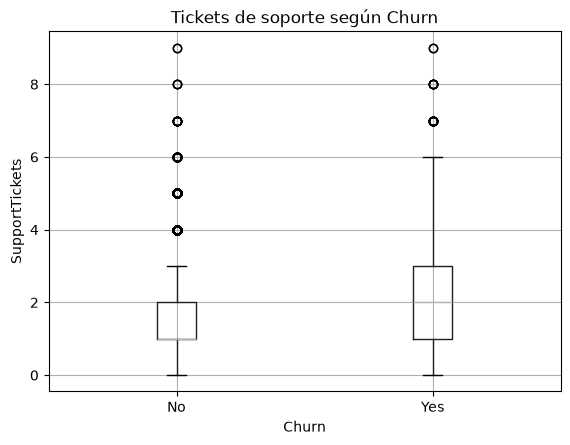

In [22]:
df.boxplot(column="SupportTickets", by="Churn")

plt.title("Tickets de soporte según Churn")
plt.suptitle("")
plt.xlabel("Churn")
plt.ylabel("SupportTickets")
plt.show()

## Quejas, tickets de soporte y Churn

La variable `Complaints` presenta una distribución muy similar entre los clientes que permanecen y los que abandonan, por lo que de manera individual no parece tener una fuerte capacidad para diferenciar el churn.

En `SupportTickets` se observa una mayor dispersión entre los clientes con `Churn = Yes`, lo que podría indicar una mayor interacción con soporte antes del abandono.

Sin embargo, existe un alto nivel de solapamiento entre ambos grupos. Por esta razón, estas variables deberán evaluarse en conjunto con características como antigüedad, tipo de contrato, cargos mensuales y otras variables de comportamiento.